# SHS consumption-basket inflation

Group inflation rates for Canadian households, 2016 to the latest CPI. Each group's rate is a consumption-basket index: Statistics Canada category price indexes, weighted by that group's Survey of Household Spending (SHS) expenditure shares.

Comparable SHS waves on this machine are **2017, 2019, and 2023**. Category dollars stay in within-year nominal dollars. The all-items deflator used in the income–consumption notebook is not applied to these shares.

Prices are the Canada CPI from table **18-10-0004** (2002=100). The annual index is the mean of the monthly index. The annual inflation rate is the year-over-year change in that mean. **2026 uses January–October only** and is shaded on the figures.

Weights inside a group are survey-weighted expenditure shares,

`share = sum(weight x category dollars) / sum(weight x total consumption)`,

for households with positive weight and positive total current consumption (`TC001`).

The denominator is total current consumption (`TC001`). Total expenditure (`TE001`) is a different total: it adds taxes, gifts, insurance and pension contributions, and mortgage principal. Those items stay out of the basket, so housing is the shelter component of consumption rather than the larger expenditure total.

Two paths are saved:

- **Fixed baskets.** The 2017, 2019, and 2023 shares are each held constant. The price index is `100 x sum(share x CPI_t / CPI_2019)`, so 2019 equals 100.
- **Updated basket.** Shares are the observed SHS basket in 2017, 2019, and 2023. Between those waves the category shares move in a straight line: 2018 is halfway from 2017 to 2019, and 2020–2022 move from the 2019 basket to the 2023 basket. Years through 2017 use the 2017 basket, and 2023 onward keeps the 2023 basket. Annual price relatives are chained with that year's basket, then rebased so 2019 equals 100.

The cumulative gap is the group's percent change in the price index since 2019, minus the same percent change in the all-items CPI. Every group is priced with the national CPI. Differences across groups come from baskets.

## Owned accommodation

CPI owned accommodation is mortgage interest, replacement cost, property taxes, homeowners' insurance, and maintenance. SHS `SH010` is the survey's spending on the owned principal residence, and that total includes mortgage payments (`SH011`).

The shelter-split basket places `SH010` on the CPI owned-accommodation index, `SH003` on rented accommodation, and `SH030` on water, fuel and electricity. The remainder of `SH001` is priced with the shelter index. This split separates renters from owners. It does not turn SHS ownership spending into the CPI user-cost concept. Mortgage principal has no price index of its own.

The primary basket avoids that mismatch by pricing all of `SH001` with the single shelter index.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

HERE = Path.cwd()
ROOT = None
for candidate in [HERE, *HERE.parents]:
    if (candidate / "code" / "category_inflation" / "run_category_inflation.py").exists():
        ROOT = candidate
        break
if ROOT is None:
    raise FileNotFoundError("Could not find the SHS project root")
sys.path.insert(0, str(ROOT / "code"))

from category_inflation.baskets import (
    AGE_ORDER,
    CATEGORY_LABELS,
    PRIMARY_CATEGORIES,
    SHELTER_CATEGORIES,
    TENURE_ORDER,
    TENURE_PRETTY,
)
from category_inflation.plots import latest_full_year
from category_inflation.run_category_inflation import main

results = main()
shares = results["shares"]
indexes = results["indexes"]
out = ROOT / "outputs" / "category_inflation"
END = latest_full_year(indexes)

Building annual category CPI...


  CPI years 2015-2026, partial years: [2026]
Loading SHS 2017, 2019, 2023 (nominal dollars)...


  households: 2017=4012, 2019=7930, 2023=5485
  extract: C:\Users\thoma\Dropbox\SHS\outputs\category_inflation\shs_household_categories.parquet
 year  n_households  n_complete_primary  n_complete_shelter  residual_share  me_gc_share  residual_minus_me_gc_share  other_shelter_share_of_tc  other_shelter_share_of_shelter  share_hh_residual_below_minus_1  share_hh_other_shelter_below_minus_1  max_abs_dollar_gap_vs_identity
 2017          4012                4012                4012        0.030652     0.030652                4.925604e-18                   0.025462                        0.088115                         0.004237                                   0.0                             0.0
 2019          7930                7930                7930        0.028546     0.028546                2.499299e-10                   0.024182                        0.083726                         0.005044                                   0.0                             0.0
 2023          5485

2023 imputed card share by income band:
 year income_band  target  weighted_mean_prop    n
 2023   under_45k    0.45            0.452249  902
 2023  45k_to_85k    0.50            0.495511 1492
 2023   above_85k    0.60            0.602417 3091


Updated primary basket at 2025 (inflation and cumulative gap vs all-items):
grouping            group  inflation   cum_gap
     all              all   0.021364  0.008083
   inc_q               Q1   0.022351  0.014347
   inc_q               Q2   0.021593  0.009846
   inc_q               Q3   0.021396  0.007649
   inc_q               Q4   0.021126  0.007230
   inc_q               Q5   0.021065  0.005967
  cons_d              D01   0.023918  0.022983
  cons_d              D02   0.023044  0.016511
  cons_d              D03   0.022429  0.012163
  cons_d              D04   0.022702  0.013581
  cons_d              D05   0.022077  0.009854
  cons_d              D06   0.021751  0.007956
  cons_d              D07   0.021525  0.007577
  cons_d              D08   0.020625  0.004120
  cons_d              D09   0.021163  0.007717
  cons_d              D10   0.020140  0.004221
age_band            30-39   0.021997  0.011031
age_band            40-54   0.021112  0.006428
age_band            55-64   0.0

## Concordance

Parents only: child categories such as child care stay inside household operations and are not given a second weight. The residual is `TC001` minus the mapped sum. On these three waves that residual lines up with miscellaneous expenditure plus games of chance, and it is priced with the all-items CPI.

Clothing is `CL030` in 2019 and 2023, and `CL001` in the 2017 diary. Alcohol, tobacco, and cannabis are `TA018` in 2019 and 2023; the 2017 aggregate is `TA001`, which has no cannabis line.

In [2]:
concordance = results["concordance"].copy()
order = {name: i for i, name in enumerate(list(PRIMARY_CATEGORIES) + list(SHELTER_CATEGORIES))}
concordance["category_label"] = concordance["category"].map(CATEGORY_LABELS)
concordance["_ord"] = concordance["category"].map(order)
concordance = concordance.sort_values(["basket", "_ord"]).drop(columns="_ord")
display(concordance)

,basket,category,cpi_product,shs_sources,notes,category_label
1,primary,shelter,Shelter,SH001,"Shelter total, including rented and owned acco...",Shelter
0,primary,food,Food,FD001,Food expenditures.,Food
2,primary,household,"Household operations, furnishings and equipment",HO001 + HF001,Household operations plus furnishings and equi...,Household operations and furnishings
3,primary,clothing,Clothing and footwear,CL030 (2017: CL001),Clothing and accessories. The 2017 diary names...,Clothing and footwear
4,primary,transportation,Transportation,TR001,Transportation.,Transportation
5,primary,health_personal,Health and personal care,HC001 + PC001,Out-of-pocket health care plus personal care.,Health and personal care
6,primary,recreation_education,"Recreation, education and reading",RE001 + ED002 + RO001,"Recreation, education, and reading materials.","Recreation, education and reading"
7,primary,alcohol_tobacco,"Alcoholic beverages, tobacco products and recr...",TA018 (2017: TA001),"Alcohol, tobacco, and cannabis. The 2017 aggre...","Alcohol, tobacco and cannabis"
8,primary,residual,All-items,TC001 - mapped sum,Priced at all-items CPI. Absorbs miscellaneous...,Residual (all-items CPI)
9,shelter_split,food,Food,FD001,Same SHS weight as the primary basket. Food ex...,Food


## Adding-up check

Mapped categories plus the residual rebuild `TC001` on every complete household. The residual share equals the share of miscellaneous expenditure plus games of chance. A few households have a residual below minus one dollar; those gaps cancel in the weighted total, which is what enters the price index. The shelter parts rebuild `SH001` (the other-shelter share of shelter is positive in every year).

In [3]:
check = results["adding_up"].copy()
pct_cols = [
    "residual_share",
    "me_gc_share",
    "residual_minus_me_gc_share",
    "other_shelter_share_of_tc",
    "other_shelter_share_of_shelter",
    "share_hh_residual_below_minus_1",
    "share_hh_other_shelter_below_minus_1",
]
shown = check.copy()
for col in pct_cols:
    shown[col] = (shown[col] * 100).round(2)
shown["max_abs_dollar_gap_vs_identity"] = shown["max_abs_dollar_gap_vs_identity"].round(6)
display(shown)

,year,n_households,n_complete_primary,n_complete_shelter,residual_share,me_gc_share,residual_minus_me_gc_share,other_shelter_share_of_tc,other_shelter_share_of_shelter,share_hh_residual_below_minus_1,share_hh_other_shelter_below_minus_1,max_abs_dollar_gap_vs_identity
0,2017,4012,4012,4012,3.07,3.07,0.0,2.55,8.81,0.42,0.0,0.0
1,2019,7930,7930,7930,2.85,2.85,0.0,2.42,8.37,0.50,0.0,0.0
2,2023,5485,5485,5485,2.51,2.51,0.0,2.85,9.05,0.35,0.0,0.0


## Basket shares in 2019

Shares below are percent of `TC001`. Shelter is a larger share for lower income quintiles, mortgage owners, and renters. Owners without a mortgage spend a smaller share on shelter and a larger share on transportation, recreation, and health.

In [4]:
def share_table(grouping, categories, basket="primary", survey_year=2019, index_order=None):
    sub = shares[
        (shares["basket"] == basket)
        & (shares["grouping"] == grouping)
        & (shares["survey_year"] == survey_year)
    ]
    wide = sub.pivot(index="group", columns="category", values="share")
    wide = wide.reindex(columns=list(categories))
    if index_order is not None:
        wide = wide.reindex(index=[g for g in index_order if g in wide.index])
    wide = (wide * 100).round(1)
    wide.columns = [CATEGORY_LABELS[c] for c in wide.columns]
    if grouping == "tenure":
        wide.index = [TENURE_PRETTY.get(g, g) for g in wide.index]
    wide.index.name = grouping
    return wide

display(share_table("inc_q", PRIMARY_CATEGORIES, index_order=[f"Q{i}" for i in range(1, 6)]))
display(share_table("tenure", PRIMARY_CATEGORIES, index_order=list(TENURE_ORDER)))
display(share_table("age_band", PRIMARY_CATEGORIES, index_order=list(AGE_ORDER)))

,Food,Shelter,Household operations and furnishings,Clothing and footwear,Transportation,Health and personal care,"Recreation, education and reading","Alcohol, tobacco and cannabis",Residual (all-items CPI)
inc_q,,,,,,,,,
Q1,15.6,33.4,10.3,4.6,15.6,6.3,8.5,3.1,2.4
Q2,16.2,30.0,11.3,4.4,16.9,7.1,8.4,2.9,2.8
Q3,15.3,28.9,11.7,4.8,19.7,6.1,8.1,2.6,2.8
Q4,15.5,27.6,11.5,5.0,19.8,6.0,9.1,2.6,2.9
Q5,14.1,27.9,11.4,4.8,19.6,5.7,11.5,2.1,3.0


,Food,Shelter,Household operations and furnishings,Clothing and footwear,Transportation,Health and personal care,"Recreation, education and reading","Alcohol, tobacco and cannabis",Residual (all-items CPI)
tenure,,,,,,,,,
Owner with mortgage,13.9,32.7,11.3,4.5,19.1,5.5,8.6,2.2,2.4
Owner free and clear,16.3,20.2,12.1,4.8,20.5,7.7,11.8,2.7,4.0
Renter,16.5,30.5,10.7,5.5,16.4,5.6,9.1,3.1,2.6


,Food,Shelter,Household operations and furnishings,Clothing and footwear,Transportation,Health and personal care,"Recreation, education and reading","Alcohol, tobacco and cannabis",Residual (all-items CPI)
age_band,,,,,,,,,
<30,13.0,29.6,11.1,5.1,20.2,4.7,11.5,2.9,1.9
30-39,15.2,31.3,12.7,5.3,17.7,4.9,8.5,2.3,2.2
40-54,14.7,29.2,10.8,4.9,19.5,5.4,10.5,2.4,2.7
55-64,15.0,26.7,11.0,4.6,20.4,6.6,9.6,2.7,3.5
65-74,16.6,26.5,11.5,3.9,17.6,8.2,8.9,3.2,3.5
75+,17.2,30.1,11.6,3.9,14.8,9.9,6.7,2.0,3.7


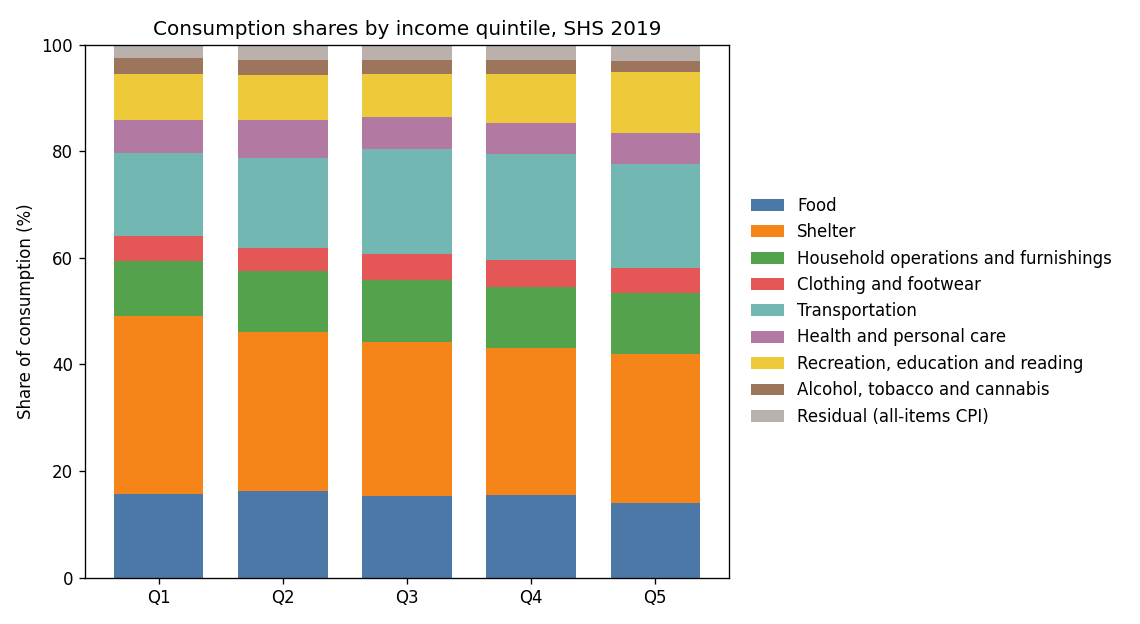

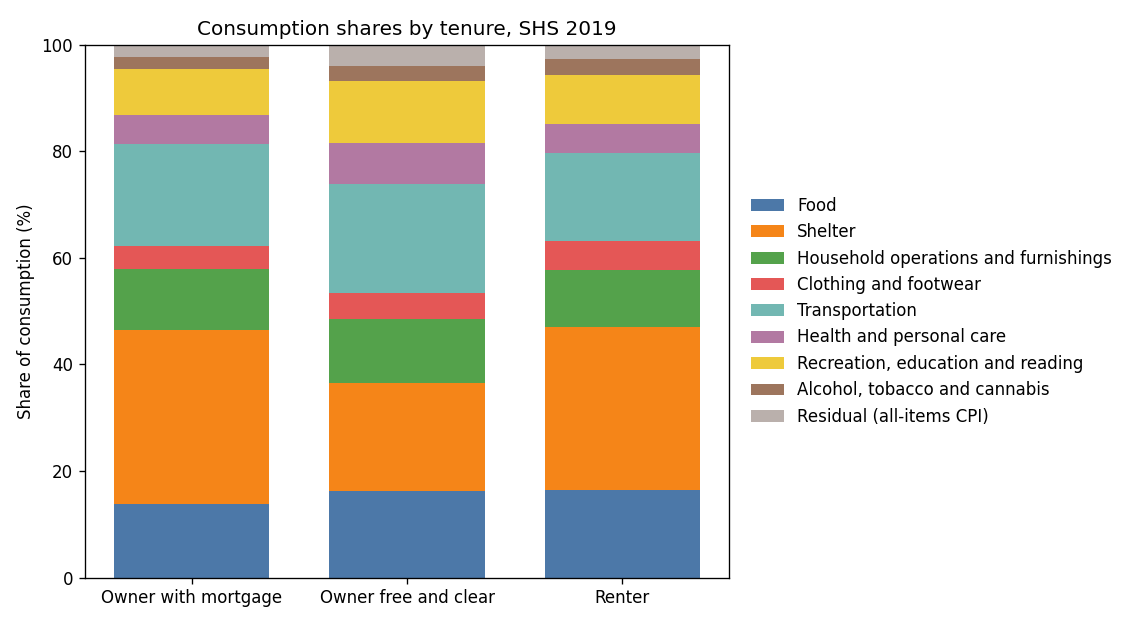

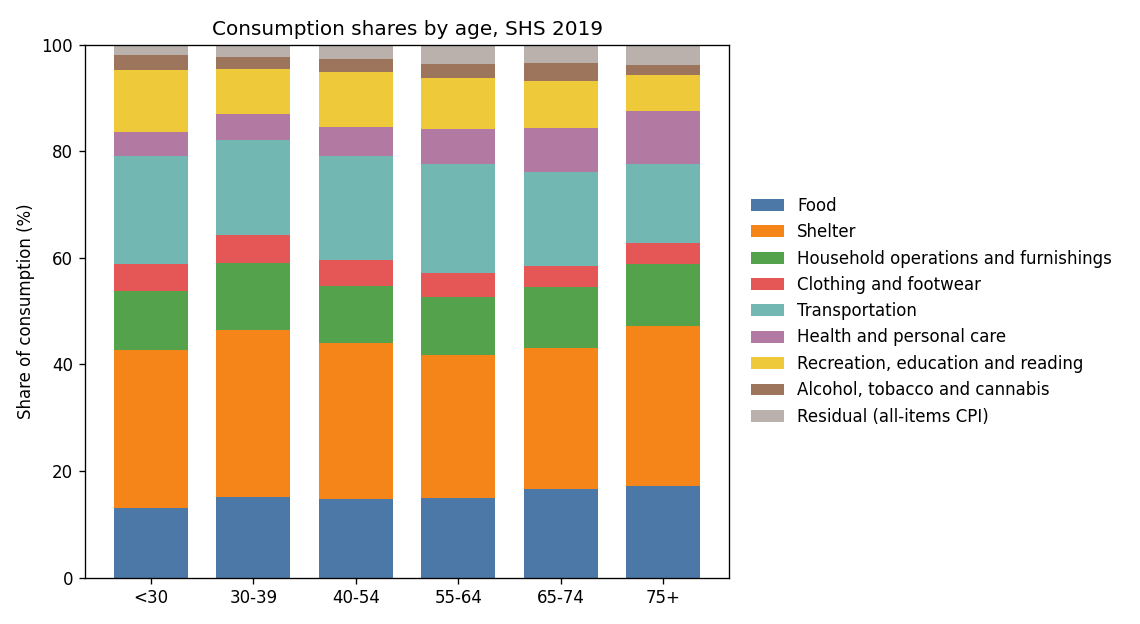

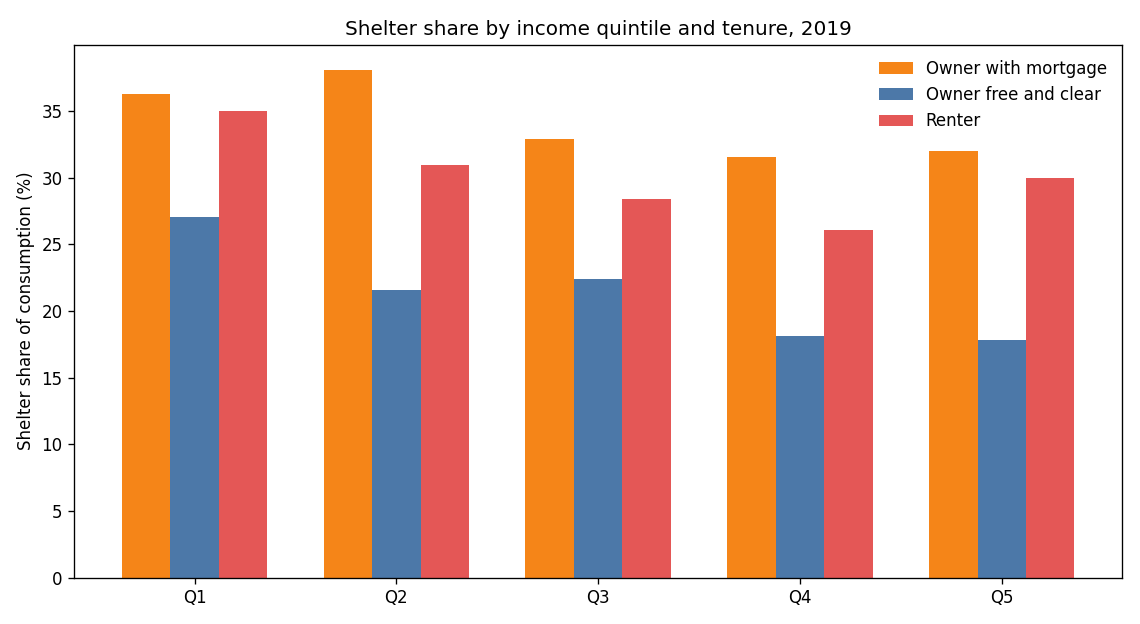

In [5]:
fig = out / "figures"
for name in [
    "shares_income_2019.png",
    "shares_tenure_2019.png",
    "shares_age_2019.png",
    "shelter_share_income_tenure_2019.png",
]:
    display(Image(filename=str(fig / name)))

## How much the baskets change

The survey waves are 2017, 2019, and 2023. `shift_pp` is half the sum of absolute category-share changes, in percentage points. A value of 2 means two percent of the group's consumption moved from one category to another.

The updated price index uses these observed baskets in a survey year. Between 2017 and 2019, and between 2019 and 2023, each category share moves in a straight line and the shares still sum to 1. Through 2017 the basket stays at the 2017 shares. From 2023 on it stays at the 2023 shares.

Share of the primary basket that moved between SHS waves (percentage points)


,basket,grouping,group,interval,shift_pp
0,primary,all,all,2017_2019,2.39
1,primary,all,all,2019_2023,4.53
2,primary,all,all,2017_2023,6.62
3,primary,inc_q,Q1,2017_2019,3.42
4,primary,inc_q,Q1,2019_2023,4.58
...,...,...,...,...,...
70,primary,tenure,owner_mortgage,2019_2023,5.68
71,primary,tenure,owner_mortgage,2017_2023,7.12
72,primary,tenure,renter,2017_2019,4.10
73,primary,tenure,renter,2019_2023,3.42


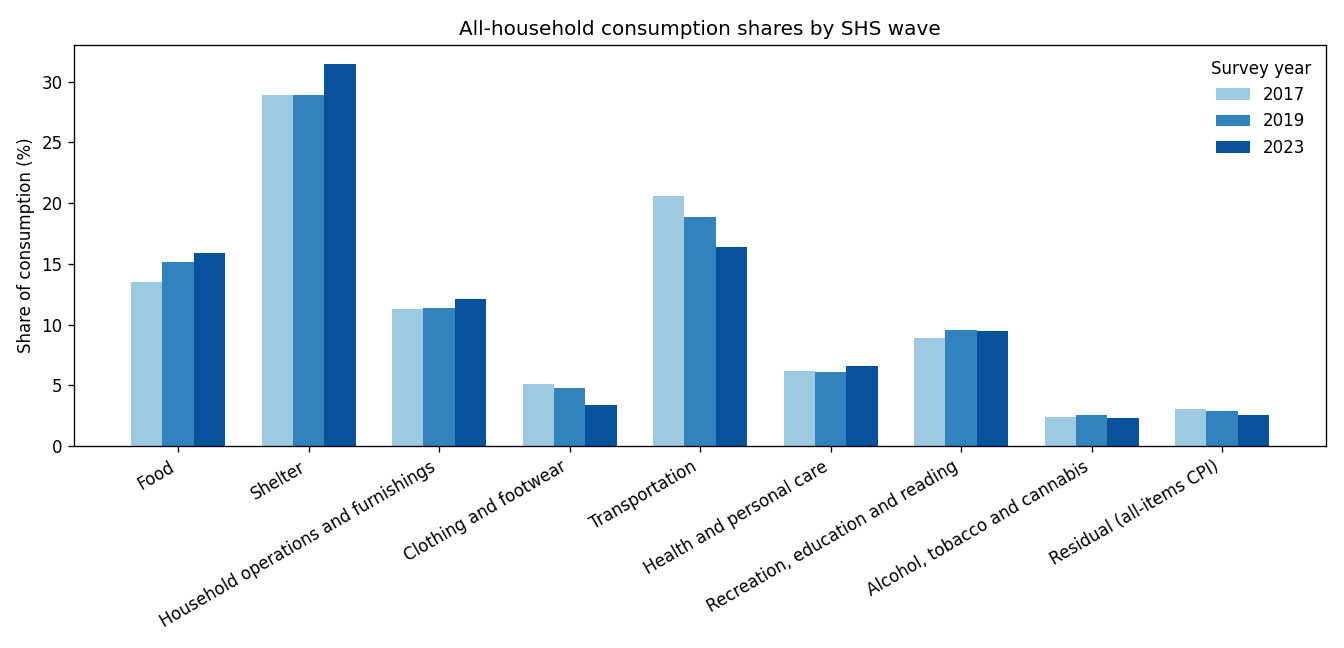

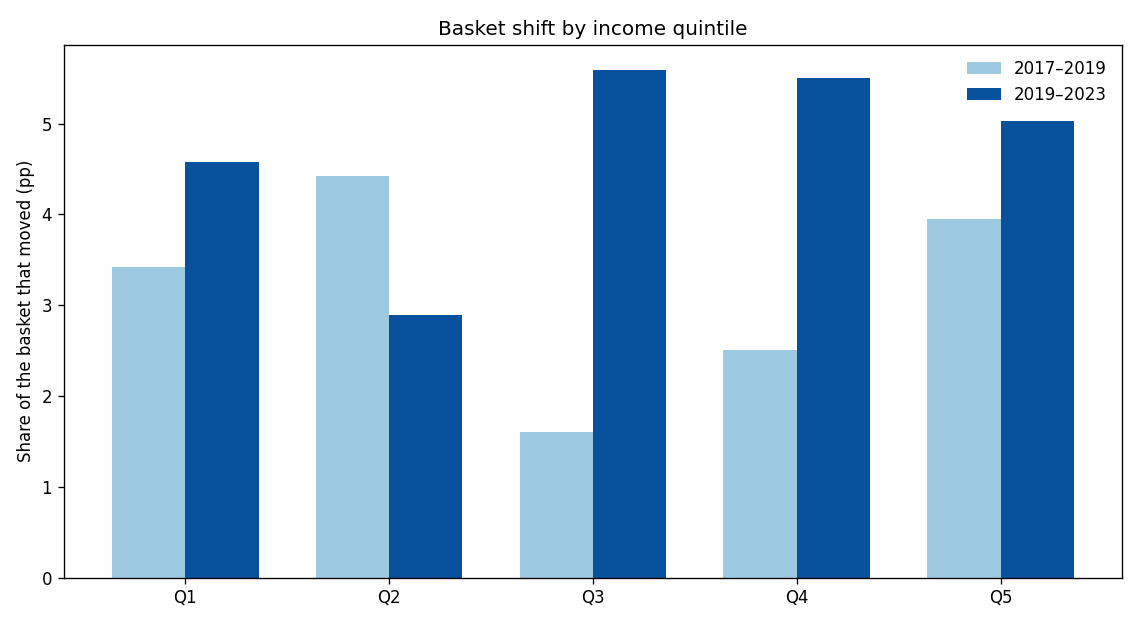

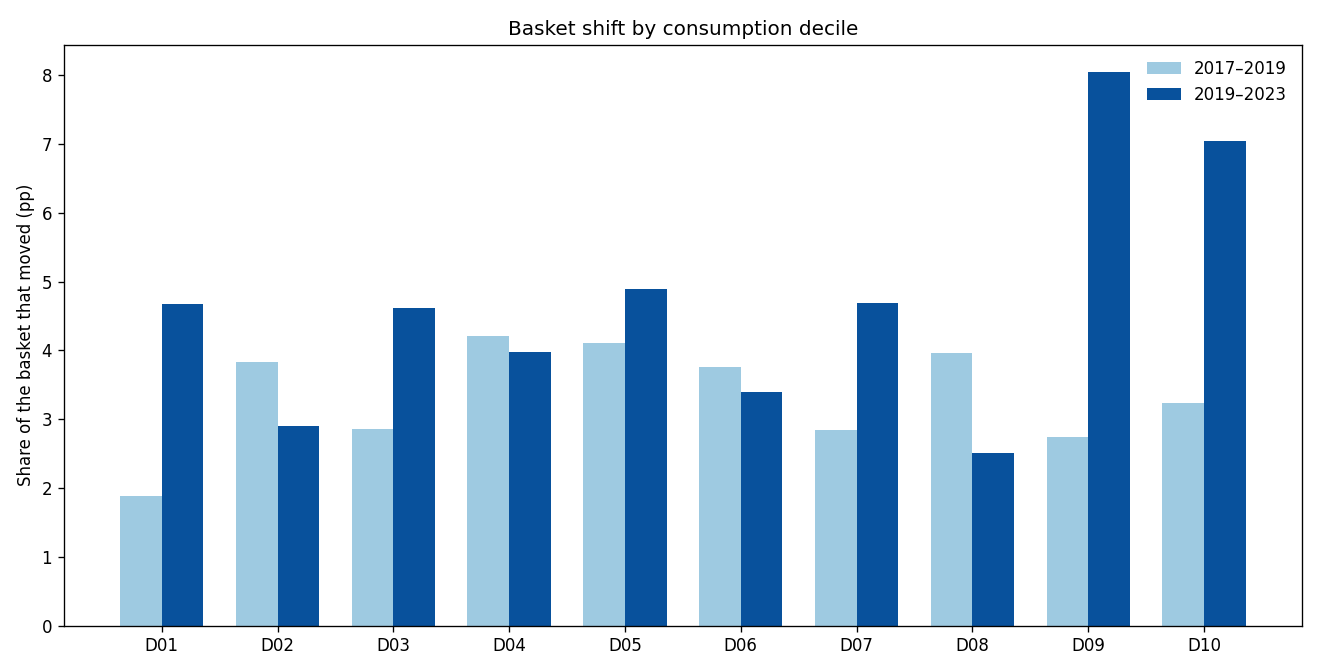

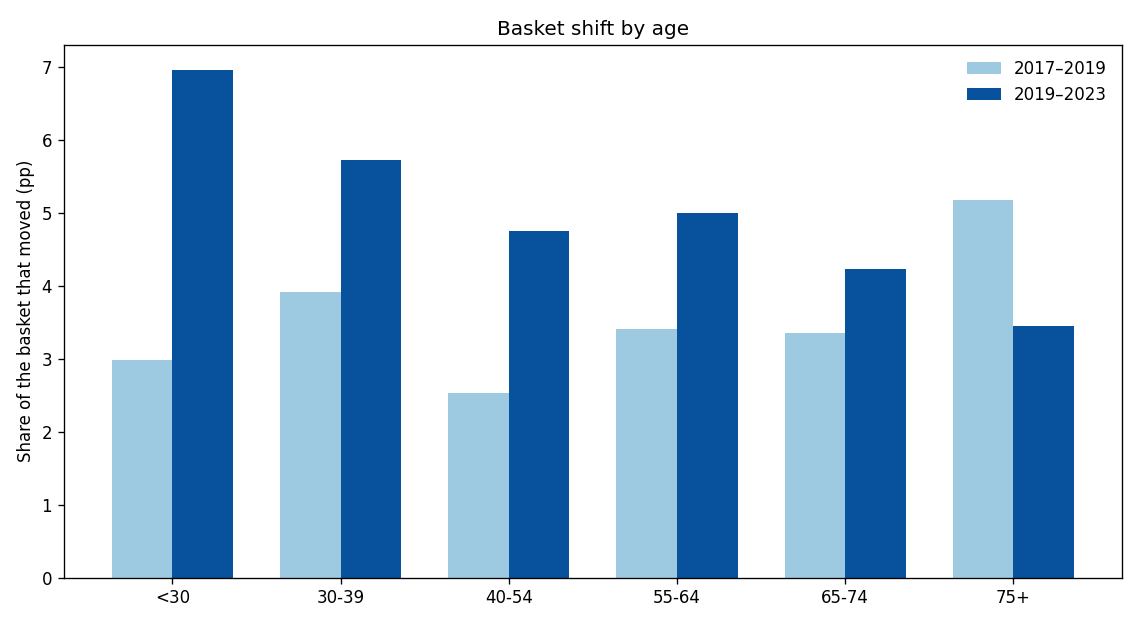

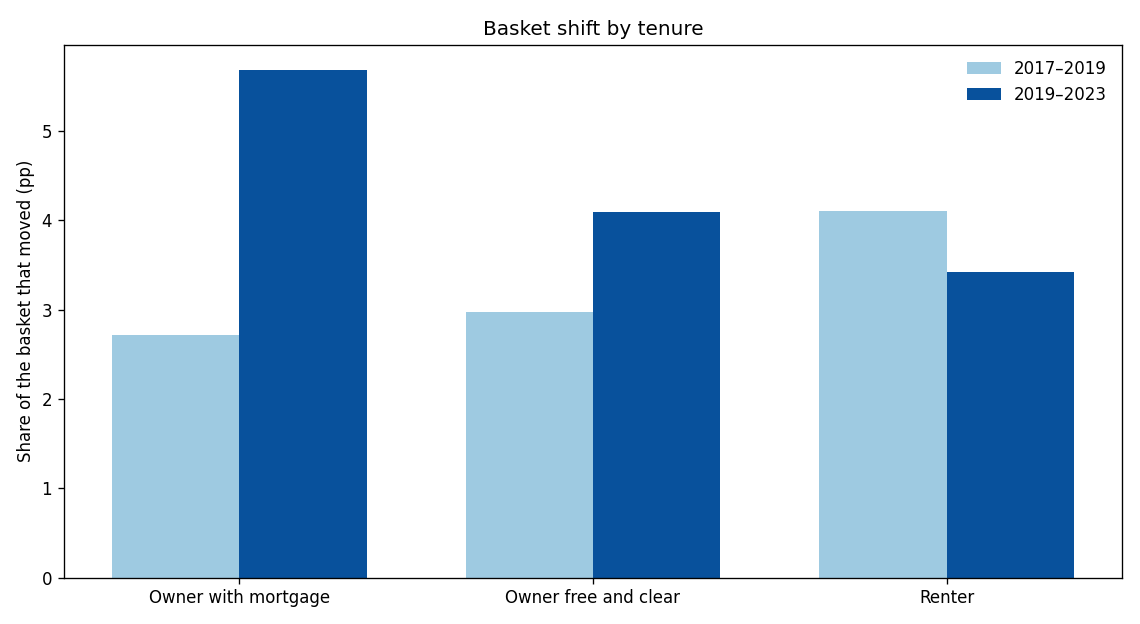

In [6]:
shift = results["basket_shift"].copy()
show = shift[
    (shift["basket"] == "primary")
    & (shift["grouping"].isin(["all", "inc_q", "cons_d", "age_band", "tenure"]))
].copy()
show["grouping"] = pd.Categorical(
    show["grouping"], ["all", "inc_q", "cons_d", "age_band", "tenure"], ordered=True
)
show["shift_pp"] = show["shift_pp"].round(2)
print("Share of the primary basket that moved between SHS waves (percentage points)")
display(show.sort_values(["grouping", "group", "interval"]))

fig = out / "figures"
for name in [
    "shares_all_waves.png",
    "basket_shift_income.png",
    "basket_shift_consumption_decile.png",
    "basket_shift_age.png",
    "basket_shift_tenure.png",
]:
    display(Image(filename=str(fig / name)))

## Inflation paths

The table is the updated basket in the latest full CPI year. Inflation is that year's rate. The cumulative gap is the percentage-point difference from all-items CPI since 2019.

The all-household row is the national SHS basket priced with these category indexes. It is close to all-items CPI and is not identical to it: the CPI uses its own basket weights. Group gaps are read against all-items, and the spread across groups is the part that comes from different SHS baskets.

Fixed 2017, 2019, and 2023 baskets give the same ordering of income quintiles. The result is not an artefact of one survey year.

The product charts are the CPI itself, before any SHS weights. One is the annual rate. The other is the percent change in each product's annual index since 2019, the same base as the basket indexes. The shelter panel splits shelter into rent, owned accommodation, and water, fuel and electricity.


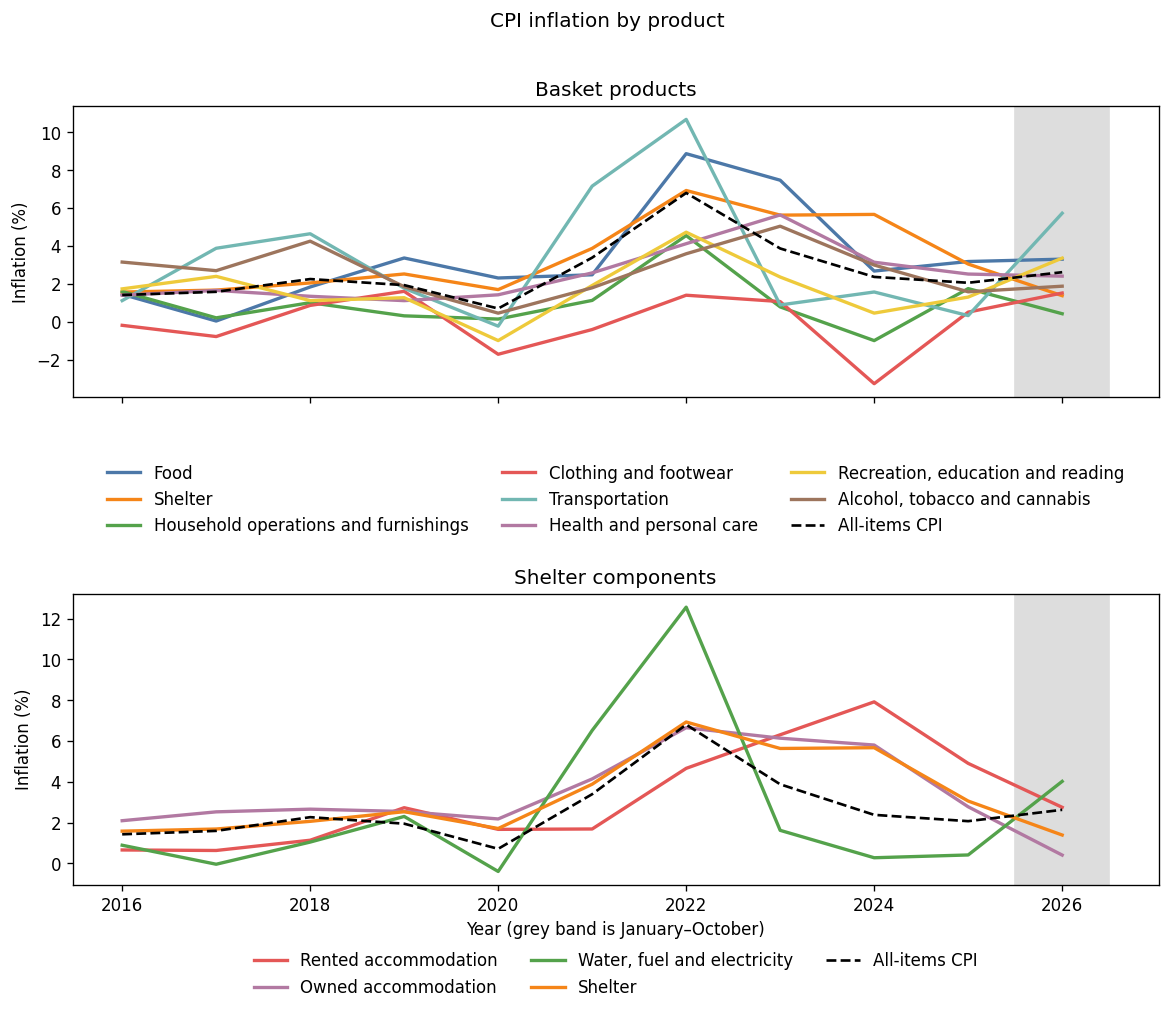

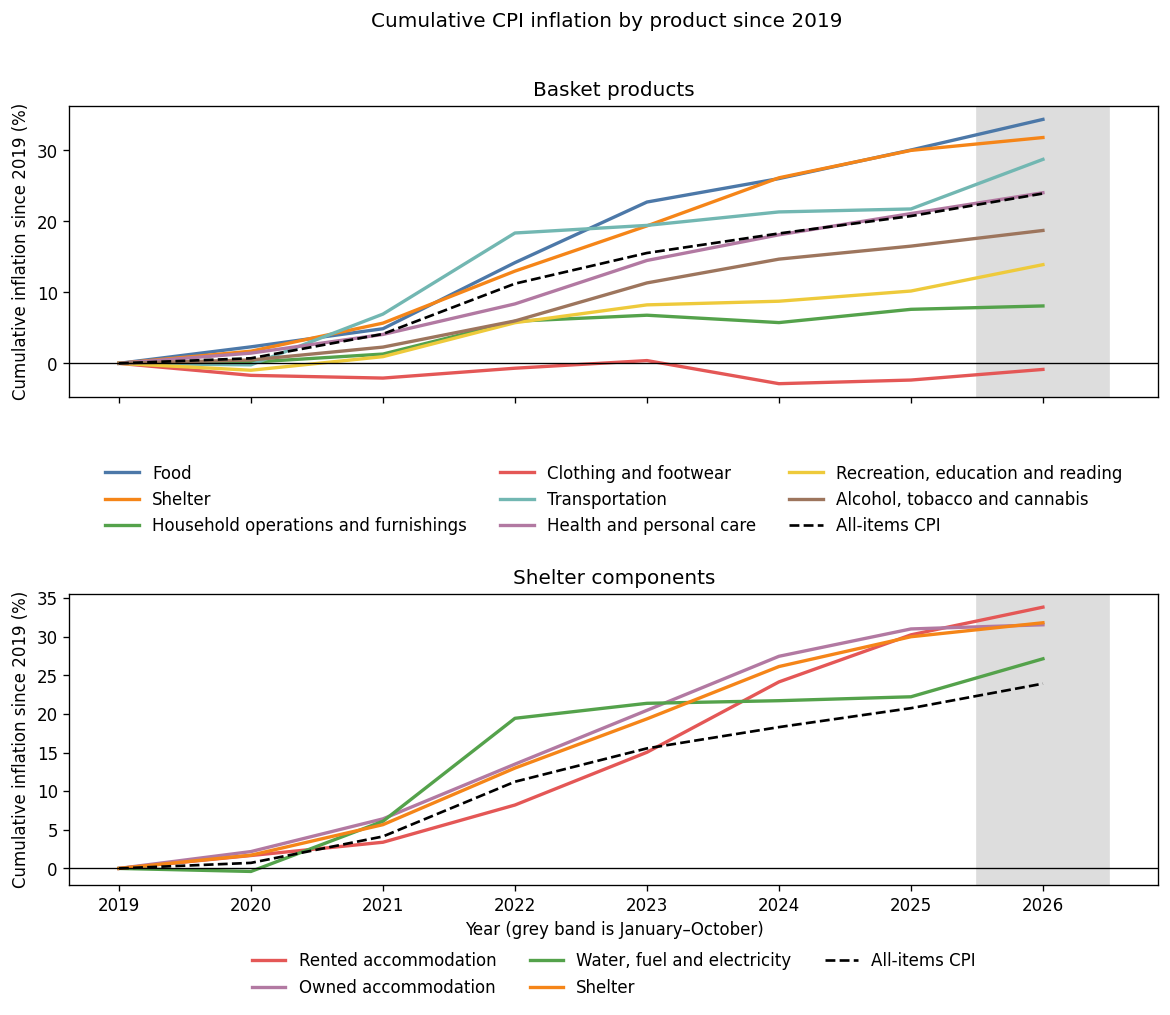

In [7]:
display(Image(filename=str(out / "figures" / "inflation_by_product.png")))
display(Image(filename=str(out / "figures" / "cum_inflation_by_product.png")))

In [8]:
def inflation_table(frame):
    out_frame = frame.copy()
    for col in ["inflation", "all_items_inflation", "cum_from_2019", "all_items_cum_from_2019"]:
        out_frame[col] = (out_frame[col] * 100).round(2)
    out_frame["inflation_gap"] = (out_frame["inflation_gap"] * 100).round(2)
    out_frame["cum_gap"] = (out_frame["cum_gap"] * 100).round(2)
    return out_frame

keep = [
    "grouping",
    "group",
    "inflation",
    "all_items_inflation",
    "inflation_gap",
    "cum_from_2019",
    "all_items_cum_from_2019",
    "cum_gap",
]
headline = indexes[
    (indexes["basket"] == "primary")
    & (indexes["path"] == "updated")
    & (indexes["year"] == END)
    & (indexes["grouping"].isin(["all", "inc_q", "age_band", "tenure"]))
].copy()
headline["grouping"] = pd.Categorical(
    headline["grouping"], ["all", "inc_q", "age_band", "tenure"], ordered=True
)
age_rank = {label: i for i, label in enumerate(AGE_ORDER)}
tenure_rank = {label: i for i, label in enumerate(TENURE_ORDER)}
headline["_g"] = headline.apply(
    lambda r: (
        int(r["group"][1]) if r["grouping"] == "inc_q"
        else age_rank.get(r["group"], 99) if r["grouping"] == "age_band"
        else tenure_rank.get(r["group"], 99)
    ),
    axis=1,
)
headline = headline.sort_values(["grouping", "_g"])
print(f"Updated primary basket, {END}")
display(inflation_table(headline)[keep])

fixed = indexes[
    (indexes["basket"] == "primary")
    & (indexes["path"] == "fixed")
    & (indexes["grouping"] == "inc_q")
    & (indexes["year"] == END)
].copy()
fixed_wide = fixed.pivot(index="group", columns="share_year", values="cum_gap")
fixed_wide = fixed_wide.reindex([f"Q{i}" for i in range(1, 6)]) * 100
fixed_wide = fixed_wide.round(2)
fixed_wide.columns = [f"{int(c)} basket" for c in fixed_wide.columns]
print(f"Cumulative gap vs all-items, 2019 to {END}, fixed baskets (percentage points)")
display(fixed_wide)

cross = indexes[
    (indexes["basket"] == "primary")
    & (indexes["path"] == "updated")
    & (indexes["grouping"] == "inc_q_x_tenure")
    & (indexes["year"] == END)
].copy()
parts = cross["group"].str.split(" | ", n=1, regex=False, expand=True)
cross["inc_q"] = parts[0]
cross["tenure"] = parts[1]
cross_wide = cross.pivot(index="inc_q", columns="tenure", values="cum_gap")
cross_wide = cross_wide.reindex(index=[f"Q{i}" for i in range(1, 6)], columns=list(TENURE_ORDER))
cross_wide = (cross_wide * 100).round(2)
cross_wide.columns = [TENURE_PRETTY[c] for c in cross_wide.columns]
print(f"Cumulative gap vs all-items, 2019 to {END}, income quintile x tenure (percentage points)")
display(cross_wide)

Updated primary basket, 2025


,grouping,group,inflation,all_items_inflation,inflation_gap,cum_from_2019,all_items_cum_from_2019,cum_gap
1329,all,all,2.14,2.07,0.06,21.55,20.74,0.81
1340,inc_q,Q1,2.24,2.07,0.16,22.17,20.74,1.43
1351,inc_q,Q2,2.16,2.07,0.09,21.72,20.74,0.98
1362,inc_q,Q3,2.14,2.07,0.07,21.50,20.74,0.76
1373,inc_q,Q4,2.11,2.07,0.04,21.46,20.74,0.72
1384,inc_q,Q5,2.11,2.07,0.03,21.33,20.74,0.60
1560,age_band,<30,2.13,2.07,0.05,21.50,20.74,0.76
1505,age_band,30-39,2.20,2.07,0.13,21.84,20.74,1.10
1516,age_band,40-54,2.11,2.07,0.04,21.38,20.74,0.64
1527,age_band,55-64,2.10,2.07,0.03,21.47,20.74,0.74


Cumulative gap vs all-items, 2019 to 2025, fixed baskets (percentage points)


,2017 basket,2019 basket,2023 basket
group,,,
Q1,1.38,1.26,1.78
Q2,0.93,0.97,1.28
Q3,0.53,0.71,0.97
Q4,0.42,0.47,1.01
Q5,-0.13,0.19,0.93


Cumulative gap vs all-items, 2019 to 2025, income quintile x tenure (percentage points)


,Owner with mortgage,Owner free and clear,Renter
inc_q,,,
Q1,2.52,0.73,1.40
Q2,1.77,0.12,0.93
Q3,1.52,-0.22,0.61
Q4,1.31,-0.62,0.61
Q5,1.08,-0.84,1.05


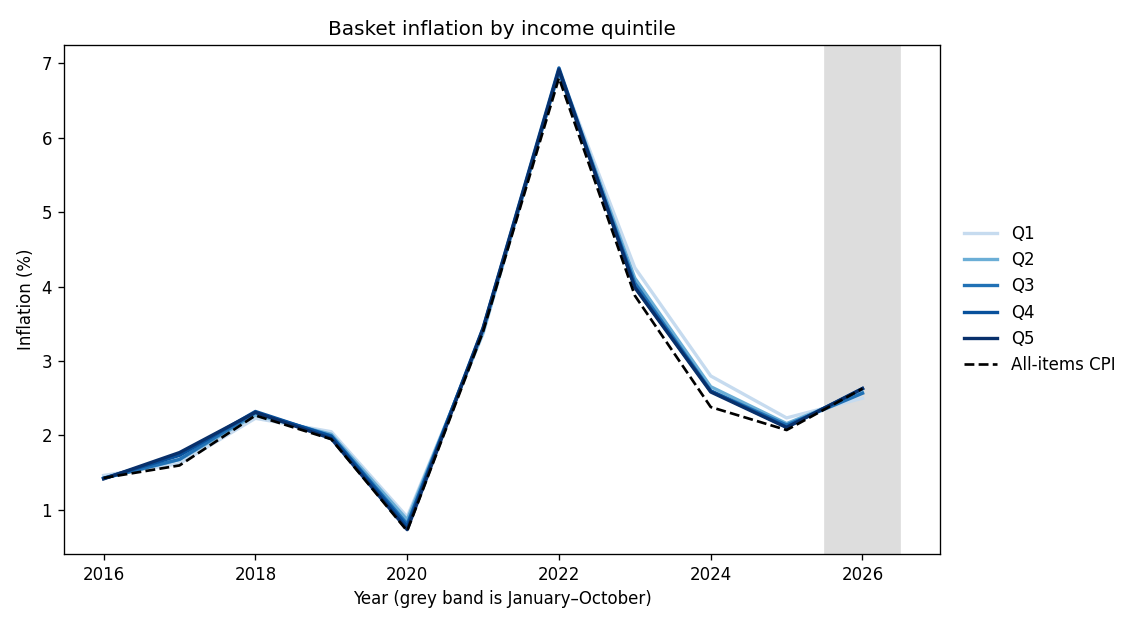

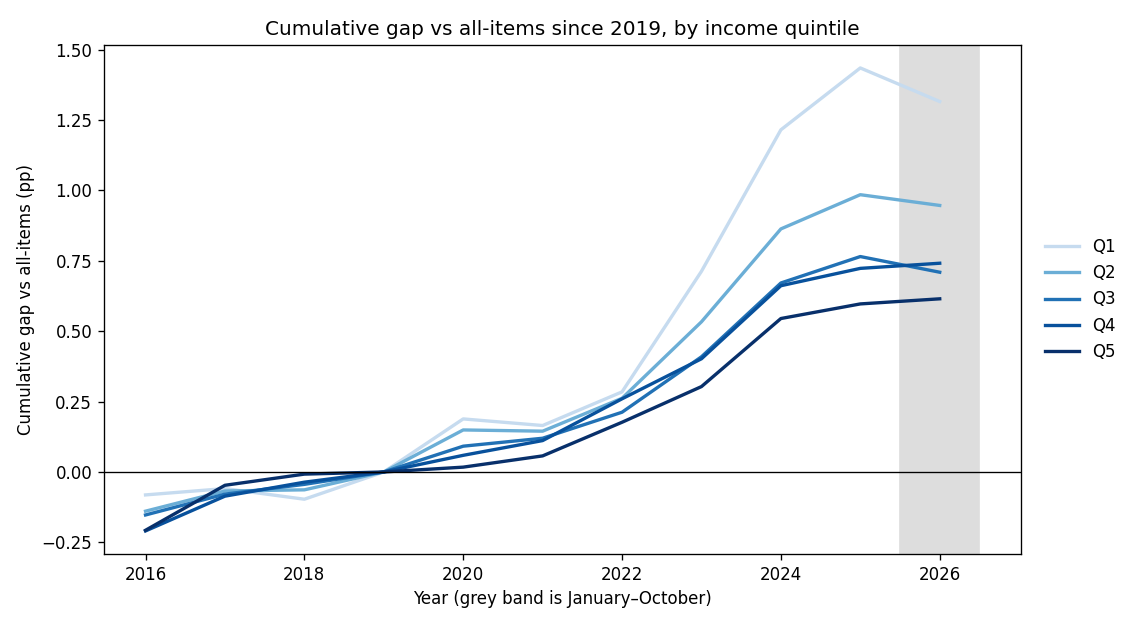

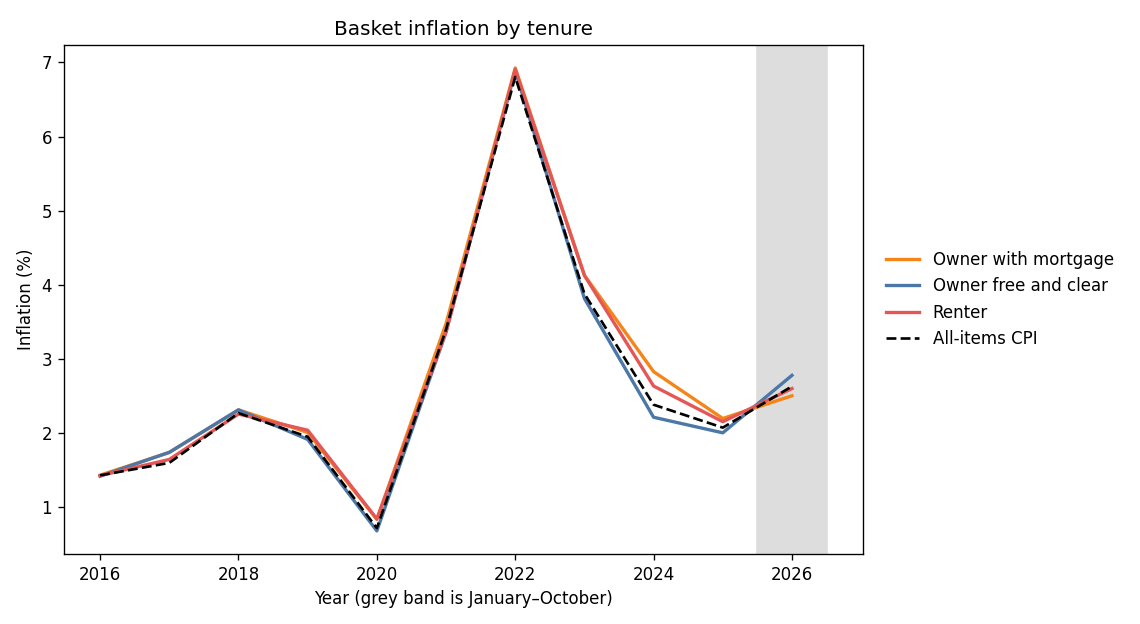

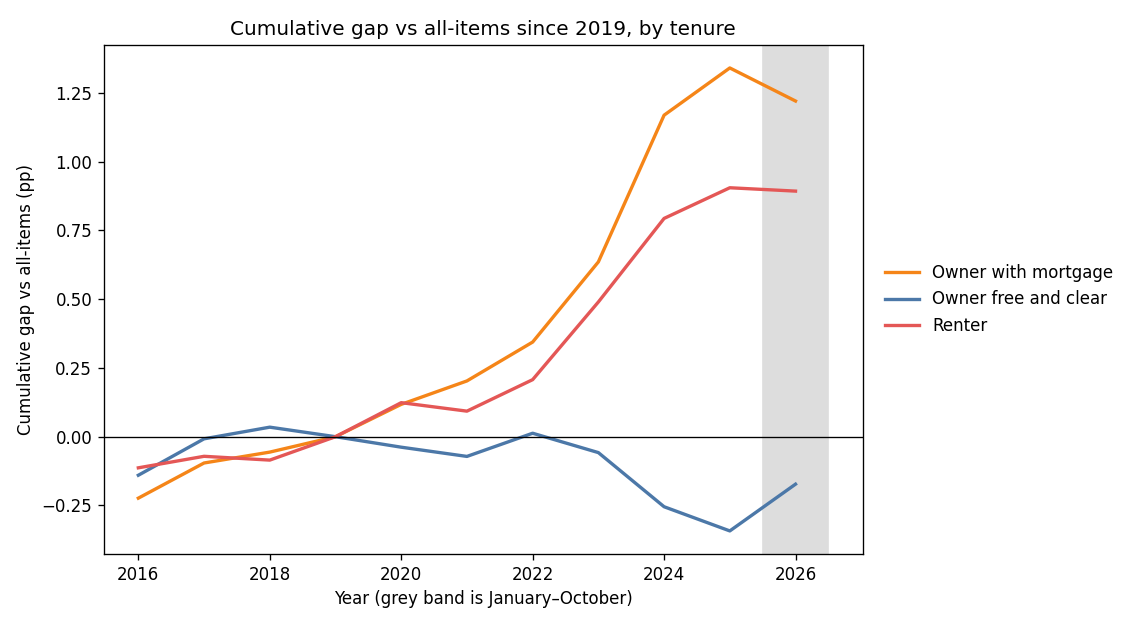

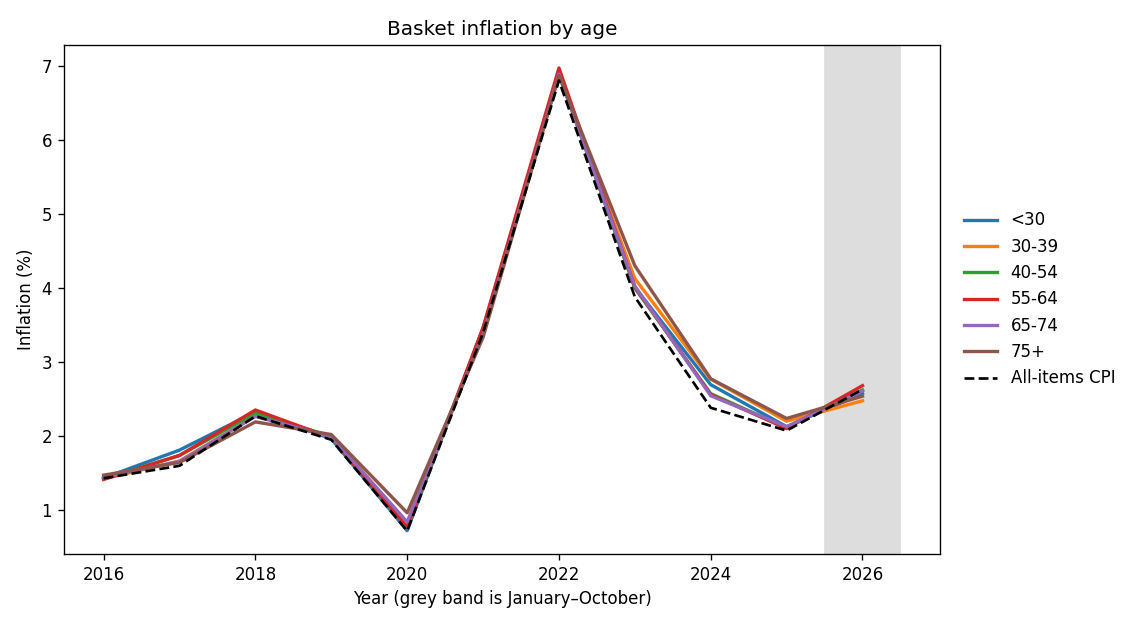

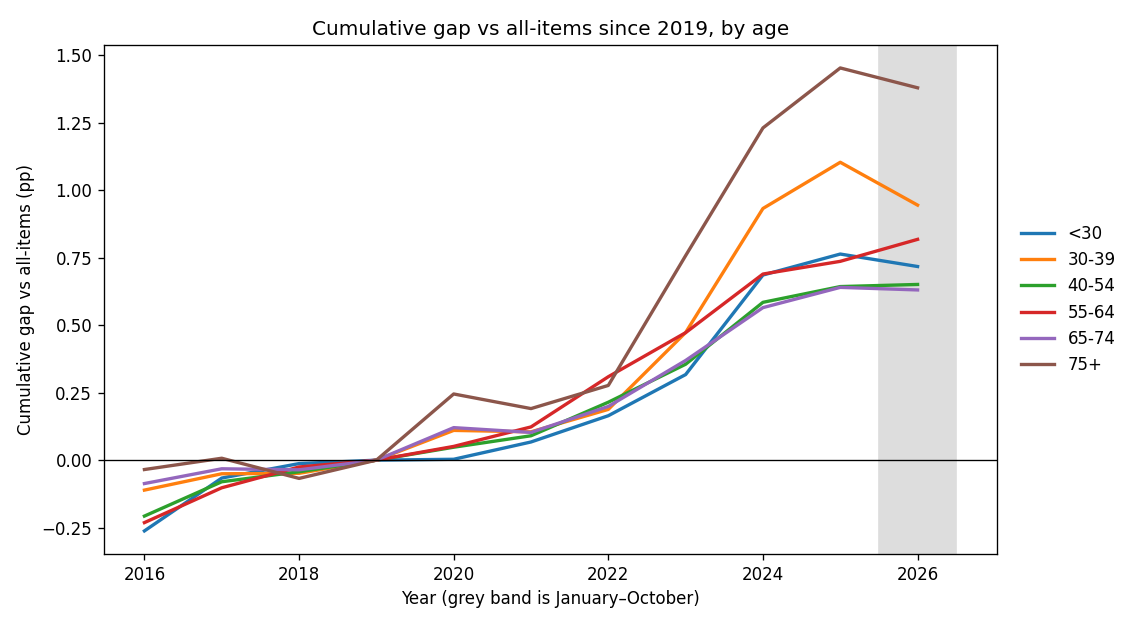

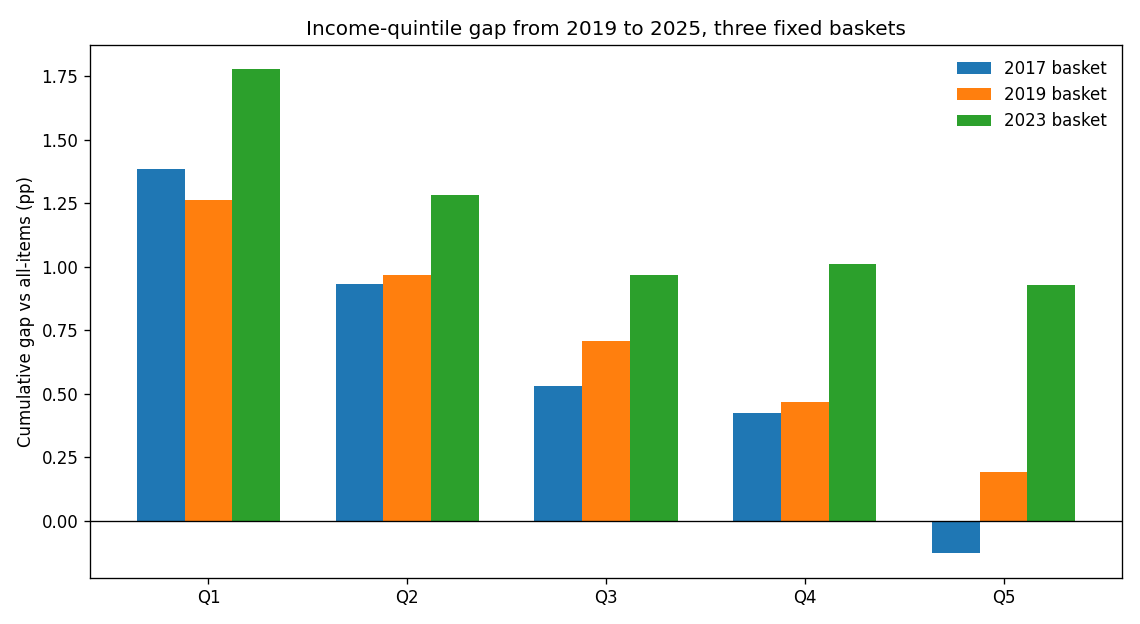

In [9]:
fig = out / "figures"
for name in [
    "inflation_income_updated.png",
    "cumgap_income_updated.png",
    "inflation_tenure_updated.png",
    "cumgap_tenure_updated.png",
    "inflation_age_updated.png",
    "cumgap_age_updated.png",
    "cumgap_income_fixed_vintages.png",
]:
    display(Image(filename=str(fig / name)))

## Shelter split

With one shelter index, mortgage owners and renters both sit above all-items after 2022, and owners without a mortgage sit slightly below. Splitting shelter changes the renter path. Rented-accommodation prices rose more slowly than all-items through 2022, then faster through 2025, so the renter index falls behind all-items and later moves ahead. Mortgage owners place a large share of spending on `SH010`, and CPI owned accommodation rose faster than all-items over this window, so their gap stays wide.

That renter path is the reason to keep the split beside the primary index. The primary index is the one that does not lean on the owned-accommodation concept above. Read `SH010` against CPI owned accommodation with that difference in mind.

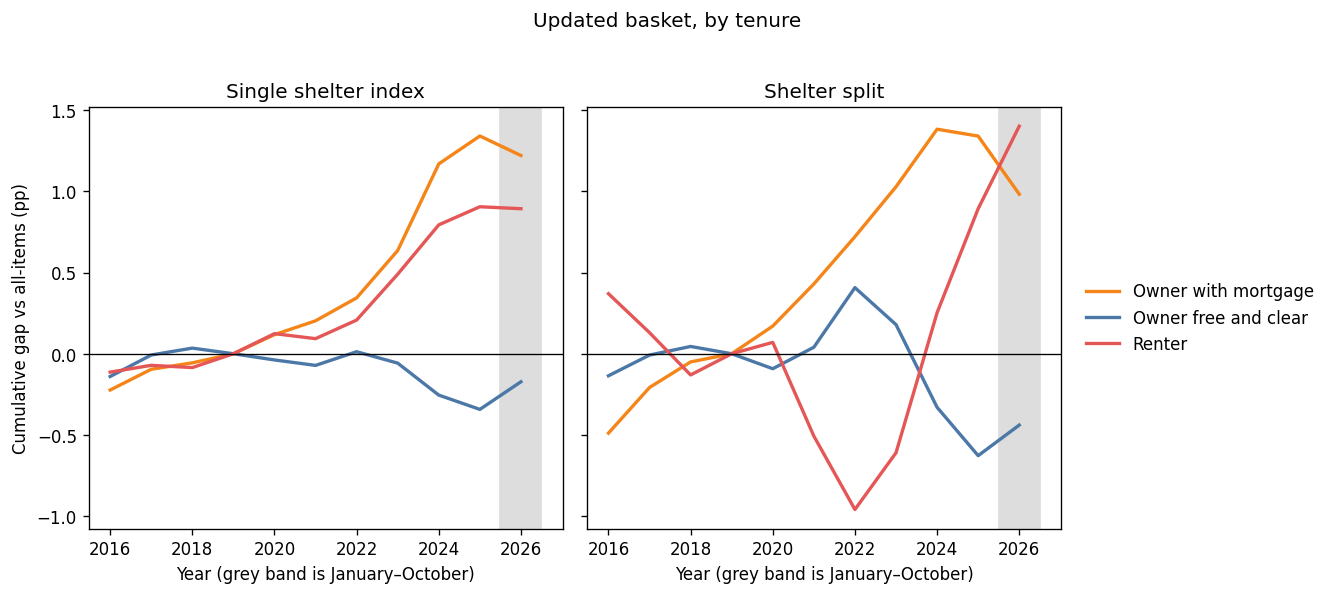

Shelter-split updated basket, 2025


,group,inflation,cum_gap
3331,Owner free and clear,1.83,-0.63
3342,Owner with mortgage,2.01,1.34
3353,Renter,2.61,0.89


In [10]:
display(Image(filename=str(out / "figures" / "cumgap_tenure_shelter_split.png")))
shelter_gap = indexes[
    (indexes["basket"] == "shelter_split")
    & (indexes["path"] == "updated")
    & (indexes["grouping"] == "tenure")
    & (indexes["year"] == END)
][["group", "inflation", "cum_gap"]].copy()
shelter_gap["group"] = shelter_gap["group"].map(TENURE_PRETTY)
shelter_gap["inflation"] = (shelter_gap["inflation"] * 100).round(2)
shelter_gap["cum_gap"] = (shelter_gap["cum_gap"] * 100).round(2)
print(f"Shelter-split updated basket, {END}")
display(shelter_gap)

## Consumption deciles

Deciles are within-year weighted ranks of total current consumption (`TC001`), labelled `D01` (lowest) through `D10` (highest). The price index is the same primary basket as the income, age, and tenure results.

`cum_gap` is the percentage-point difference from all-items CPI since 2019. `cum_gap_vs_all_households` subtracts the all-household SHS basket, so it is the decile's gap relative to the national consumption basket. `D10-D01` is the top decile minus the bottom decile.

Updated primary basket by consumption decile, 2025


,year,group,inflation,cum_gap,inflation_vs_all_households,cum_gap_vs_all_households
99,2025,D01,2.39,2.30,0.26,1.49
100,2025,D02,2.30,1.65,0.17,0.84
101,2025,D03,2.24,1.22,0.11,0.41
102,2025,D04,2.27,1.36,0.13,0.55
103,2025,D05,2.21,0.99,0.07,0.18
104,2025,D06,2.18,0.80,0.04,-0.01
105,2025,D07,2.15,0.76,0.02,-0.05
106,2025,D08,2.06,0.41,-0.07,-0.40
107,2025,D09,2.12,0.77,-0.02,-0.04
108,2025,D10,2.01,0.42,-0.12,-0.39


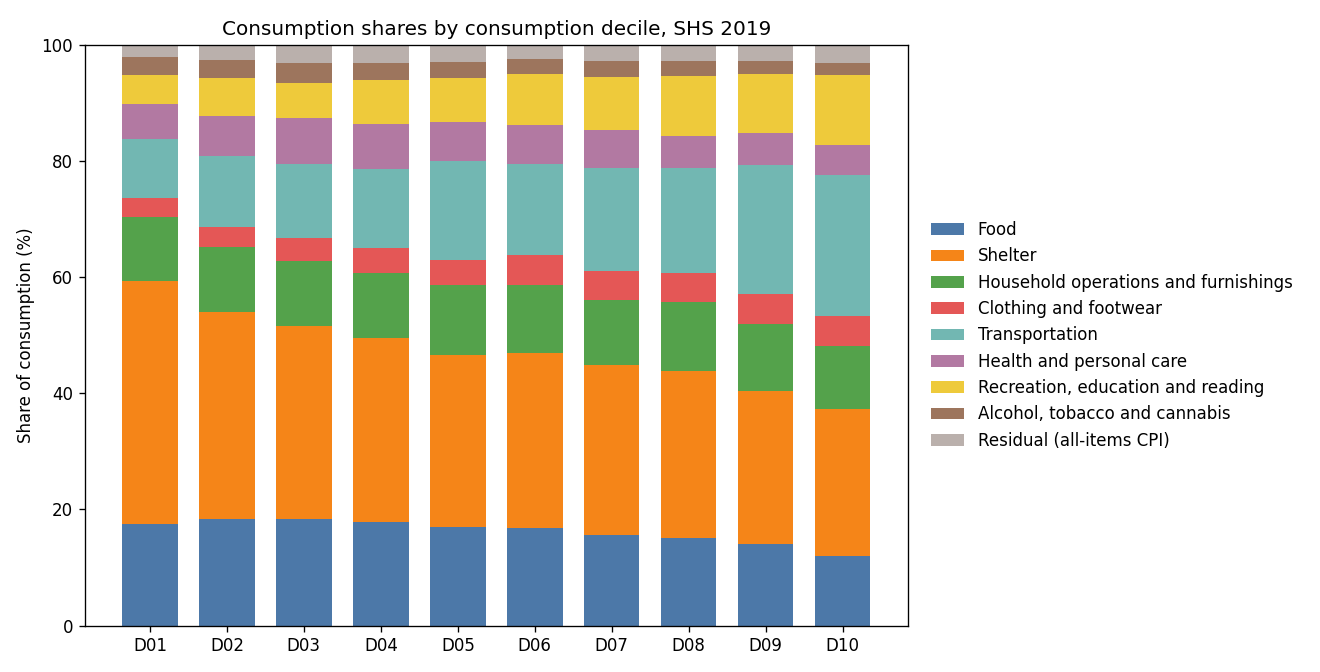

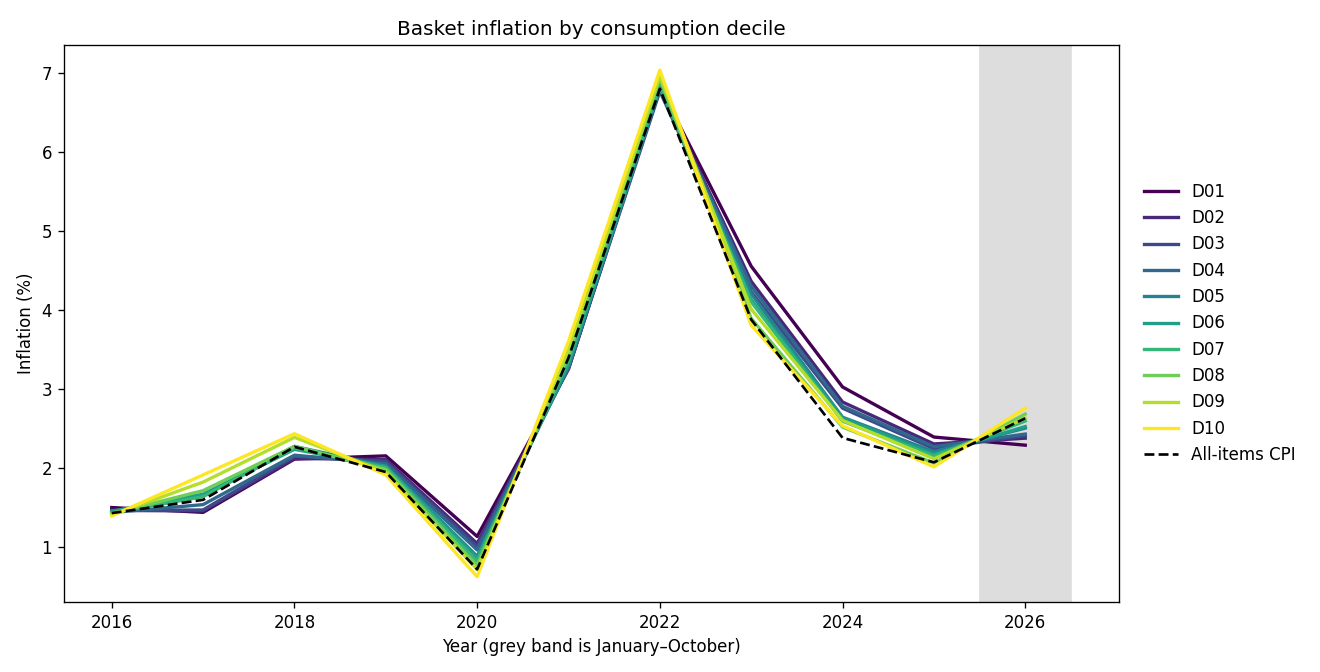

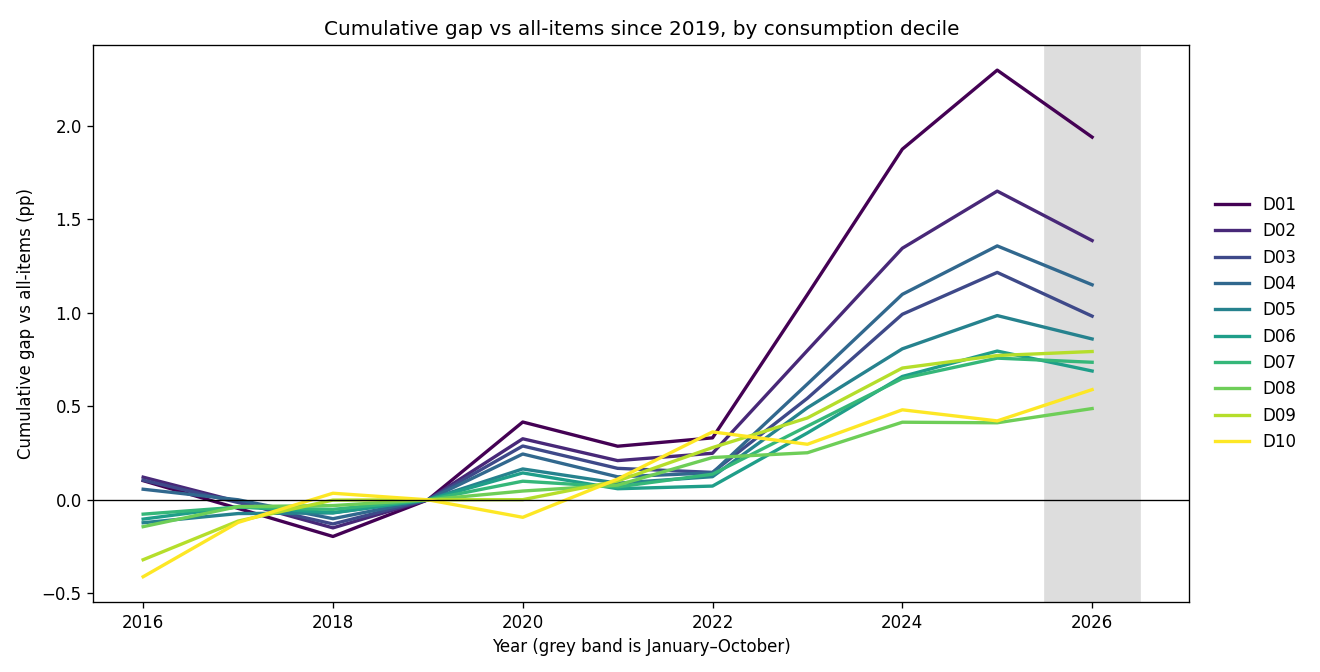

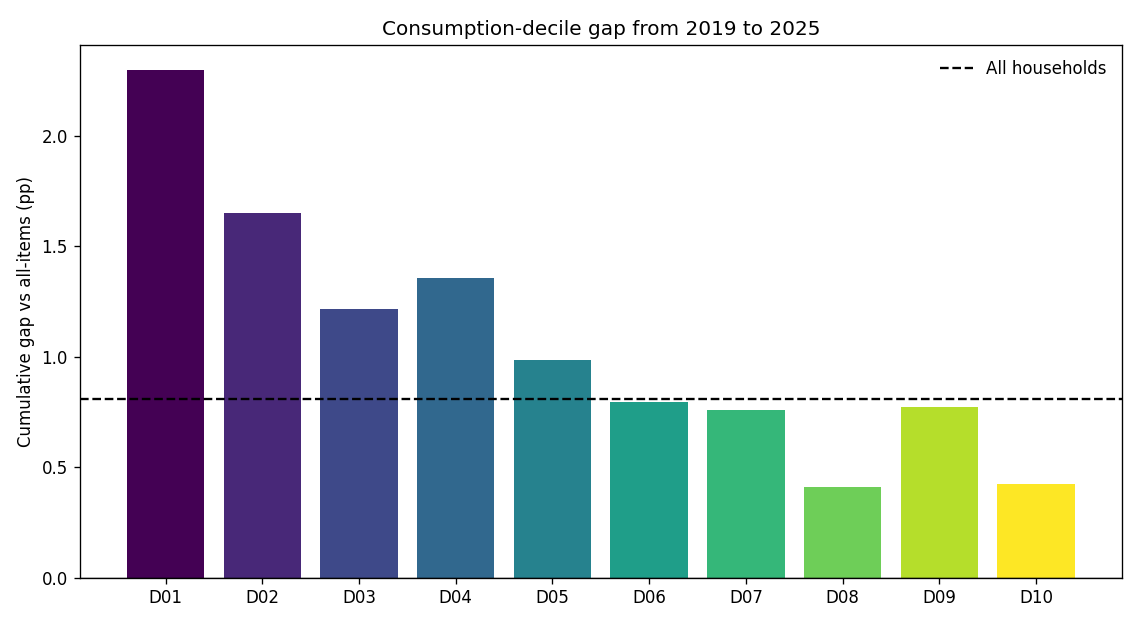

In [11]:
from category_inflation.baskets import CONS_DECILE_ORDER

deciles = results["deciles"].copy()
show = deciles[deciles["year"] == END].copy()
order = list(CONS_DECILE_ORDER) + ["D10-D01"]
show["group"] = pd.Categorical(show["group"], categories=order, ordered=True)
show = show.sort_values("group")
for col in ["inflation", "cum_gap", "inflation_vs_all_households", "cum_gap_vs_all_households"]:
    show[col] = (show[col] * 100).round(2)
print(f"Updated primary basket by consumption decile, {END}")
display(show.drop(columns=["partial_year"]))

fig = out / "figures"
for name in [
    "shares_consumption_decile_2019.png",
    "inflation_consumption_decile_updated.png",
    "cumgap_consumption_decile_updated.png",
    "cumgap_consumption_decile_bar.png",
]:
    display(Image(filename=str(fig / name)))

## Imputed credit-card consumption

The SHS public file does not record credit-card spending. `imputed_cc_prop` is the logistic curve fit in `code/logistic_cc_fit.ipynb`, frozen at location 4,500, scale 170,676.25, and ceiling 0.846. It was calibrated so that 2023 weighted means match external targets of 45%, 50%, and 60% for incomes under $45k, $45–85k, and above $85k.

`cc_consumption = imputed_cc_prop x TC001`. That is the notebook's consumption-based card spend, not the total-expenditure version. The same nominal-dollar curve is applied in 2017 and 2019. The location and scale were fit to 2023 incomes.

The propensity is one number per household. Scaling every category by that number leaves the household's basket unchanged, so card spending is a dollar variable and not a separate price index.

In [12]:
bands = results["cc_bands"].copy()
bands["weighted_mean_prop"] = bands["weighted_mean_prop"].round(3)
bands["target"] = bands["target"].round(2)
print("2023 weighted mean imputed card share, against the fit targets")
display(bands)

summary = results["cc_summary"]
decile_cc = summary[(summary["grouping"] == "cons_d") & (summary["year"] == 2023)].copy()
decile_cc["group"] = pd.Categorical(decile_cc["group"], categories=list(CONS_DECILE_ORDER), ordered=True)
decile_cc = decile_cc.sort_values("group")
decile_cc["weighted_mean_prop"] = (decile_cc["weighted_mean_prop"] * 100).round(1)
for col in ["weighted_mean_cc_consumption", "weighted_mean_tc001"]:
    decile_cc[col] = decile_cc[col].round(0)
print("2023 card propensity and mean card consumption by consumption decile")
display(
    decile_cc[
        ["group", "n", "weighted_mean_prop", "weighted_mean_cc_consumption", "weighted_mean_tc001"]
    ]
)

2023 weighted mean imputed card share, against the fit targets


,year,income_band,target,weighted_mean_prop,n
0,2023,under_45k,0.45,0.452,902
1,2023,45k_to_85k,0.50,0.496,1492
2,2023,above_85k,0.60,0.602,3091


2023 card propensity and mean card consumption by consumption decile


,group,n,weighted_mean_prop,weighted_mean_cc_consumption,weighted_mean_tc001
26,D01,480,46.4,10255.0,22046.0
27,D02,588,48.4,16254.0,33545.0
29,D03,548,50.0,21335.0,42659.0
25,D04,580,52.0,26841.0,51559.0
31,D05,561,52.9,32223.0,60924.0
23,D06,573,55.0,39130.0,71178.0
32,D07,617,56.1,47411.0,84429.0
24,D08,476,58.3,57854.0,99271.0
30,D09,539,59.5,70913.0,119104.0
28,D10,523,63.9,112558.0,175387.0


## Files

- `outputs/category_inflation/cpi_category_annual.csv` — annual category CPI from 2015 (the lag for the 2016 rate) through the latest month in the StatCan file
- `outputs/category_inflation/concordance.csv` — SHS sources and CPI products
- `outputs/category_inflation/shs_household_categories.parquet` — household extract with weights, groups, and nominal category dollars
- `outputs/category_inflation/adding_up_by_year.csv` — identity check
- `outputs/category_inflation/shares_by_group.csv` — expenditure shares
- `outputs/category_inflation/basket_change.csv` — category shares at each wave and the percentage-point change
- `outputs/category_inflation/basket_shift.csv` — share of each group's basket that moved between waves
- `outputs/category_inflation/shares_interpolated.csv` — yearly basket, linear between waves and fixed at the 2023 shares afterward
- `outputs/category_inflation/group_inflation.csv` — fixed and updated indexes, inflation rates, and gaps versus all-items

- `outputs/category_inflation/decile_differentials.csv` — consumption-decile gaps versus all-items and versus all households
- `outputs/category_inflation/cc_income_band_check.csv` — 2023 card-share check against 45/50/60
- `outputs/category_inflation/cc_spend_by_group.csv` — imputed card propensity and card consumption by group
- `outputs/category_inflation/figures/` — share and inflation charts

Rebuild with `python code/category_inflation/run_category_inflation.py`.